# 05 KPI analysis and reconciliation

> **Synthetic data, sampled simulation.** 768 simulated runs compared with 19,708 scheduled runs (3.9%). Not IRCTC or Indian Railways network-wide data. No forecasts. Associations are not causes.

**Purpose.** Compute the approved KPIs in Python (`analytics/kpi.py`, written independently of the Phase 3 module so the reconciliation is a real check) and reconcile them with `reports/kpi_reference_values.csv`, the monthly reference `monthly_kpis.csv` and the values produced by the Phase 4 SQL layer. Definitions are never adjusted to force agreement.

In [1]:
# Setup: find the project root, make python/src importable, load shared helpers (the data is only READ)
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data" / "processed" / "cleaned").exists())
sys.path.insert(0, str(ROOT / "python" / "src"))
import pandas as pd, numpy as np
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from analytics import data_loader as dl, validation, cleaning, kpi, eda, SYNTHETIC_NOTE
from analytics import statistics as stats
print(SYNTHETIC_NOTE)
%matplotlib inline
import matplotlib.pyplot as plt

Synthetic data, sampled simulation (768 simulated runs of 19,708 scheduled). Not IRCTC or Indian Railways network-wide data; no forecasts.


In [2]:
ds = dl.load_dataset()
clean = cleaning.run_cleaning(ds.tables); facts = clean.facts
monthly = kpi.monthly_kpis(facts)
pf, bf, ef, cf, rf = (facts[k] for k in ("passenger_fact", "booking_fact", "event_fact", "class_run_fact", "run_fact"))
kpis = kpi.compute_kpis(pf, bf, ef, cf, rf)

## 1. KPI catalogue: definitions and denominators

Demand per available seat is an **exploratory measure, not an approved KPI**.

In [3]:
display(kpi.kpi_table(kpis))

,kpi_key,kpi,value,definition,denominator,status
0,total_bookings,Booking volume,"201,182.0000",count of bookings,none,approved
1,total_passengers,Passenger volume,"405,200.0000",count of passengers (all final statuses),none,approved
2,confirmed_bookings,Fully confirmed booking count,"146,020.0000",bookings where every passenger finished Confirmed,none,approved
3,mixed_bookings,Mixed-status booking count,"4,625.0000",bookings whose passengers finished with differ...,none,approved
4,passenger_cancellation_rate,Passenger cancellation rate,0.1382,cancelled passengers / total passengers,total passengers,approved
5,booking_cancellation_rate,Booking-based cancellation rate,0.1323,fully cancelled bookings / total bookings,total bookings,approved
6,wl_demand,Initial waitlist demand,"36,876.0000",passengers waitlisted at booking time,none,approved
7,wl_clearance_rate,Waitlist clearance rate,0.1922,initially waitlisted passengers who finished C...,initial waitlist demand,approved
8,wl_uncleared,Uncleared waitlist passengers,"24,200.0000",passengers still Waitlisted at chart preparati...,none,approved
9,occupancy,Seat occupancy,0.7349,(Confirmed + 0.5 x RAC passengers) / seat supp...,seat supply,approved


## 2. Reconciliation with `reports/kpi_reference_values.csv`

Tolerances: counts exact; INR 0.005; shares 0.00005; per-run and minute values 0.0001.

In [4]:
rec = kpi.reconcile(kpis, ds.reference['kpi_reference'])
display(rec)
print(rec.Status.value_counts().to_dict())

,KPI,Reference_Value,Python_Value,Difference,Status
0,total_bookings,"201,182.0000","201,182.0000",0.0000,PASS
1,total_passengers,"405,200.0000","405,200.0000",0.0000,PASS
2,confirmed_bookings,"146,020.0000","146,020.0000",0.0000,PASS
3,mixed_bookings,"4,625.0000","4,625.0000",0.0000,PASS
4,cancelled_bookings,"26,619.0000","26,619.0000",0.0000,PASS
5,cancelled_passengers,"55,980.0000","55,980.0000",0.0000,PASS
6,passenger_cancellation_rate,0.1382,0.1382,0.0000,PASS
7,booking_cancellation_rate,0.1323,0.1323,0.0000,PASS
8,gross_value,"612,966,953.0000","612,966,953.0000",0.0000,PASS
9,refund_total,"107,083,527.0000","107,083,527.0000",0.0000,PASS


{'PASS': 31}


## 3. Monthly KPIs and reconciliation (24 months x 40 columns)

In [5]:
display(monthly[['journey_month', 'total_bookings', 'bookings_per_run', 'passenger_cancellation_rate', 'wl_clearance_rate', 'occupancy', 'otp', 'bookings_growth', 'bookings_per_run_growth']].head(8))
rec_m = kpi.reconcile_monthly(monthly, ds.reference['monthly_reference'])
print(len(rec_m), 'comparisons:', rec_m.Status.value_counts().to_dict())

,journey_month,total_bookings,bookings_per_run,passenger_cancellation_rate,wl_clearance_rate,occupancy,otp,bookings_growth,bookings_per_run_growth
0,2024-09,5944,185.7500,0.1323,0.1347,0.5839,0.8065,NaN,NaN
1,2024-10,7727,241.4688,0.1382,0.1727,0.6835,0.8065,0.3000,0.3000
2,2024-11,7934,247.9375,0.1353,0.2116,0.7017,0.7097,0.0268,0.0268
3,2024-12,7457,233.0312,0.1293,0.1610,0.6619,0.8125,-0.0601,-0.0601
4,2025-01,7939,248.0938,0.1375,0.1568,0.6891,0.7097,0.0646,0.0646
5,2025-02,7165,223.9062,0.1317,0.1271,0.6511,0.5938,-0.0975,-0.0975
6,2025-03,9243,288.8438,0.1350,0.1882,0.7936,0.7742,0.2900,0.2900
7,2025-04,9150,285.9375,0.1378,0.1939,0.7757,0.8065,-0.0101,-0.0101


960 comparisons: {'PASS': 960}


## 4. Python vs the Phase 4 SQL values

The SQL values come from `reports/phase4_kpi_reconciliation.csv`, produced on PostgreSQL 16. **PostgreSQL 18.4 on Windows has not been executed or validated yet.**

In [6]:
sql_cmp = kpi.compare_with_sql(kpis, ds.reference['phase4_kpi'])
print(len(sql_cmp), 'KPIs compared:', sql_cmp.Status.value_counts().to_dict())
display(sql_cmp.head(8))

31 KPIs compared: {'PASS': 31}


,KPI,SQL_Value,Python_Value,Difference,Status
0,avg_delay,19.0201,19.0201,0.0000,PASS
1,avg_fare_per_booking,"3,046.8280","3,046.8280",0.0000,PASS
2,avg_fare_per_passenger,"1,512.7516","1,512.7516",0.0000,PASS
3,booked_seats,"313,345.5000","313,345.5000",0.0000,PASS
4,booking_cancellation_rate,0.1323,0.1323,0.0000,PASS
5,bookings_per_run,261.9557,261.9557,0.0000,PASS
6,cancelled_bookings,"26,619.0000","26,619.0000",0.0000,PASS
7,cancelled_passengers,"55,980.0000","55,980.0000",0.0000,PASS


## 5. Monthly growth metrics

Monthly Booking Growth uses the previous month's bookings as the denominator. Because 32 runs are simulated every month, growth in per-run bookings is the sampling-safe companion.

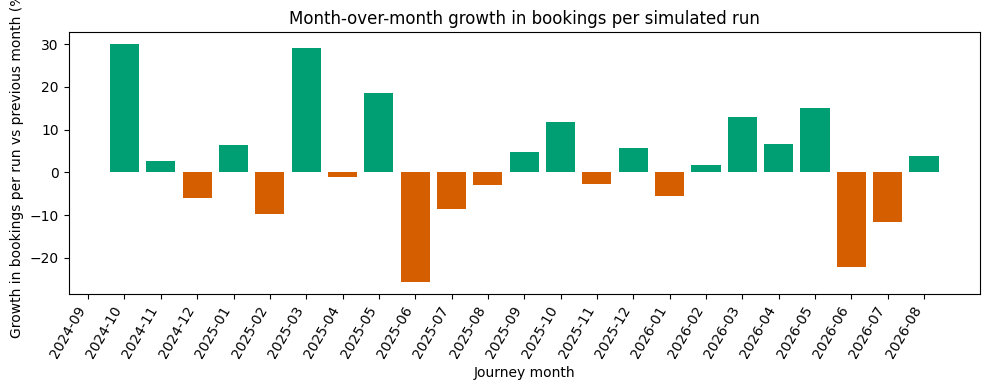

In [7]:
fig, ax = plt.subplots(figsize=(10, 4)); ax.bar(monthly.journey_month, monthly.bookings_per_run_growth * 100, color=['#009E73' if v >= 0 else '#D55E00' for v in monthly.bookings_per_run_growth.fillna(0)])
ax.set_ylabel('Growth in bookings per run vs previous month (%)'); ax.set_xlabel('Journey month'); ax.set_title('Month-over-month growth in bookings per simulated run'); plt.xticks(rotation=60, ha='right'); ax.grid(axis='x', alpha=0); plt.tight_layout(); plt.show()